In [1]:
# libraries: data handling, numeric ops, plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
     


In [2]:
import pandas as pd

df = pd.read_csv(r"D:\Food delivery.csv")

df.head(10)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30
5,0x9bb4,HYDRES09DEL03,22,4.8,17.431668,78.408321,17.461668,78.438321,11-03-2022,21:20:00,21:30:00,conditions Cloudy,Jam,0,Buffet,motorcycle,1,No,Urban,(min) 26
6,0x95b4,RANCHIRES15DEL01,33,4.7,23.369746,85.339820,23.479746,85.449820,04-03-2022,19:15:00,19:30:00,conditions Fog,Jam,1,Meal,scooter,1,No,Metropolitian,(min) 40
7,0x9eb2,MYSRES15DEL02,35,4.6,12.352058,76.606650,12.482058,76.736650,14-03-2022,17:25:00,17:30:00,conditions Cloudy,Medium,2,Meal,motorcycle,1,No,Metropolitian,(min) 32
8,0x1102,HYDRES05DEL02,22,4.8,17.433809,78.386744,17.563809,78.516744,20-03-2022,20:55:00,21:05:00,conditions Stormy,Jam,0,Buffet,motorcycle,1,No,Metropolitian,(min) 34
9,0xcdcd,DEHRES17DEL01,36,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55:00,22:10:00,conditions Fog,Jam,2,Snack,motorcycle,3,No,Metropolitian,(min) 46


In [3]:
# Rows x columns
df.shape
     


(45593, 20)

In [4]:

# Dtypes + null counts
df.info()
     

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [5]:
# Values may be stored as strings even when they look numeric — check the actual type
type(df['Delivery_person_Age'][0])
     

str

In [6]:
# Note the messy formatting: categories arrive as "conditions Sunny", plus a literal "conditions NaN"
df['Weatherconditions'].value_counts()
     

Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

In [7]:
# Those "conditions NaN" rows are missing weather stored as text, not real nulls yet
df[df['Weatherconditions']=='conditions NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
74,0xa9f,BANGRES13DEL01,NaN,NaN,12.935662,77.614130,12.975662,77.654130,11-03-2022,NaN,15:30:00,conditions NaN,NaN,1,Drinks,scooter,0,No,Metropolitian,(min) 19
120,0x6e2,VADRES06DEL01,NaN,NaN,22.312790,73.170283,22.422790,73.280283,02-04-2022,NaN,18:25:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25
250,0x1b50,PUNERES16DEL01,NaN,NaN,18.536718,73.830327,18.646718,73.940327,08-03-2022,NaN,21:25:00,conditions NaN,NaN,3,Buffet,motorcycle,1,Yes,Urban,(min) 43
348,0x4c1,BANGRES13DEL02,NaN,NaN,12.935662,77.614130,13.065662,77.744130,02-03-2022,NaN,00:05:00,conditions NaN,NaN,3,Drinks,scooter,1,No,Metropolitian,(min) 26
425,0xc003,DEHRES13DEL02,NaN,NaN,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,22:30:00,conditions NaN,NaN,3,Snack,scooter,1,No,Metropolitian,(min) 20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45332,0x2950,VADRES04DEL02,50,6,0.000000,0.000000,0.020000,0.020000,19-03-2022,NaN,10:40:00,conditions NaN,NaN,3,Drinks,electric_scooter,1,No,Urban,(min) 28
45394,0xdc4,RANCHIRES02DEL03,NaN,NaN,0.000000,0.000000,0.030000,0.030000,05-03-2022,NaN,17:25:00,conditions NaN,NaN,3,Buffet,bicycle,1,No,Metropolitian,(min) 21
45504,0x461,BANGRES07DEL02,NaN,NaN,-12.978453,-77.643685,12.998453,77.663685,17-03-2022,NaN,09:30:00,conditions NaN,NaN,3,Meal,scooter,1,No,NaN,(min) 24
45518,0x863,INDORES05DEL01,NaN,NaN,22.727021,75.884167,22.737021,75.894167,19-03-2022,NaN,11:40:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25


# Basic Data Cleaning

In [8]:
df['Weatherconditions']

0             conditions Sunny
1            conditions Stormy
2        conditions Sandstorms
3             conditions Sunny
4            conditions Cloudy
                 ...          
45588         conditions Windy
45589         conditions Windy
45590        conditions Cloudy
45591        conditions Cloudy
45592           conditions Fog
Name: Weatherconditions, Length: 45593, dtype: str

In [9]:
temp= "conditions Fog"

In [10]:
temp.split(" ")[1] if pd.notnull(temp)  else temp

'Fog'

In [11]:
# Weatherconditions arrives as "conditions Sunny" — keep only the actual word

df['Weatherconditions']=df['Weatherconditions'].apply(lambda temp :temp.split(" ")[1] if pd.notnull(temp) else temp)
     

In [12]:
df['Weatherconditions']

0             Sunny
1            Stormy
2        Sandstorms
3             Sunny
4            Cloudy
            ...    
45588         Windy
45589         Windy
45590        Cloudy
45591        Cloudy
45592           Fog
Name: Weatherconditions, Length: 45593, dtype: str

In [13]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='str')

In [14]:

# All text (object) columns

df.select_dtypes(include='object').columns

C:\Users\arnab\AppData\Local\Temp\ipykernel_19408\1539116408.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival',
       'City', 'Time_taken(min)'],
      dtype='str')

In [15]:
# The literal string is padded with spaces — this is why we strip() before comparing to 'NaN'
' NaN '
     

' NaN '

In [16]:
import numpy as np

for col in df.select_dtypes(include='str').columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace('NaN', np.nan)


In [17]:
# After strip + replace, confirm no literal 'NaN' strings remain in a numeric column

df[df['Delivery_person_Age']=='NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  str    
 3   Delivery_person_Ratings      43685 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [19]:

# Target column still stored as text, e.g. "(min) 24"

type(df['Time_taken(min)'][0])

str

In [20]:
# Same one-value test for the target's "(min) 24" format

temp='(min) 24'
     


In [21]:
# Take the number after the space and cast to int

int(temp.split(" ")[1]) if pd.notnull(temp) else temp
     

24

In [22]:
# Target cleanup: "(min) 24" -> 24 (int). Keep real NaNs as NaN instead of crashing on them

df['Time_taken(min)']=df['Time_taken(min)'].apply(lambda temp :int(temp.split(" ")[1]) if pd.notnull(temp) else temp)
     

In [23]:
type(df['Time_taken(min)'][0])

numpy.int64

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  str    
 3   Delivery_person_Ratings      43685 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [25]:

# Looks numeric but may be stored as text — worth confirming before we cast

df['multiple_deliveries'].value_counts()

multiple_deliveries
1    28159
0    14095
2     1985
3      361
Name: count, dtype: int64

In [26]:

# Force genuinely numeric columns to numeric dtype; errors='coerce' turns any
# leftover bad values into NaN instead of raising, so we can impute them next

for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col]=pd.to_numeric(df[col],errors='coerce')


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [28]:
# Summary stats — a quick way to spot impossible values (e.g. a rating > 5) 

df.describe()
     

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [29]:

# Ratings shouldn't exceed 5 — clip any bad values (e.g. 6.0) back to the valid max

df[df['Delivery_person_Ratings']>5]['Delivery_person_Ratings']

3586     6.0
4714     6.0
5169     6.0
5362     6.0
5651     6.0
6394     6.0
7031     6.0
7681     6.0
9499     6.0
9535     6.0
10100    6.0
10737    6.0
12297    6.0
13257    6.0
13652    6.0
14106    6.0
14907    6.0
14944    6.0
16798    6.0
17145    6.0
17708    6.0
18977    6.0
19382    6.0
20269    6.0
21320    6.0
22416    6.0
23375    6.0
24237    6.0
24918    6.0
25285    6.0
26052    6.0
27221    6.0
27399    6.0
28315    6.0
28974    6.0
29535    6.0
30579    6.0
30943    6.0
31233    6.0
32326    6.0
33533    6.0
34688    6.0
38007    6.0
38020    6.0
38561    6.0
38649    6.0
39699    6.0
40223    6.0
41105    6.0
41969    6.0
42072    6.0
42835    6.0
45332    6.0
Name: Delivery_person_Ratings, dtype: float64

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [31]:
df['Road_traffic_density'].value_counts()

Road_traffic_density
Low       15477
Jam       14143
Medium    10947
High       4425
Name: count, dtype: int64

In [32]:
# Numeric columns: fill missing values with the median (robust to outliers/skew) 

for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col]=df[col].fillna(df[col].median())
     


In [33]:
# Categorical columns: fill missing values with the mode (most frequent category)

for col in ['Weatherconditions','Road_traffic_density','Festival','City']:
  df[col].fillna(df[col].mode()[0],inplace=True)

C:\Users\arnab\AppData\Local\Temp\ipykernel_19408\3364802065.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].mode()[0],inplace=True)


In [34]:
# Fill missing categorical values with the mode

for col in ['Weatherconditions', 'Road_traffic_density', 'Festival', 'City']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

# EDA

# 3. Exploratory data analysis

In [36]:
df['Time_taken(min)'].describe()

count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64

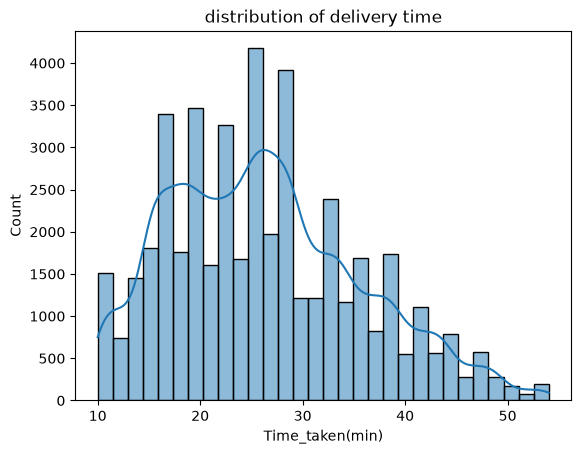

In [37]:
sns.histplot(df['Time_taken(min)'],bins=30,kde =True)
plt.title("distribution of delivery time")
plt.show()
     

In [38]:
df['Road_traffic_density'].mode()[0]

'Low'

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [40]:
df['Road_traffic_density'].value_counts()

Road_traffic_density
Low       16078
Jam       14143
Medium    10947
High       4425
Name: count, dtype: int64

In [41]:
# Does traffic density relate to delivery time? Compare the groups

df.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count','mean','median','std'])
     

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.240000,27.0,8.396012
Jam,14143,31.176624,31.0,9.940904
Low,16078,21.464175,21.0,6.988438
Medium,10947,26.699644,27.0,8.560179


In [42]:
df['Weatherconditions'].value_counts()

Weatherconditions
Fog           8270
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
Name: count, dtype: int64

In [43]:
# Weather vs delivery time

df.groupby('Weatherconditions')['Time_taken(min)'].agg(['count','mean','median','std'])
     

,count,mean,median,std
Weatherconditions,,,,
Cloudy,7536,28.917330,28.0,10.084352
Fog,8270,28.739541,28.0,10.100816
Sandstorms,7495,25.875517,26.0,8.618434
Stormy,7586,25.870815,26.0,8.473273
Sunny,7284,21.856947,20.0,8.327210
Windy,7422,26.118836,26.0,8.615702


In [44]:
df['Festival'].value_counts()

Festival
No     44697
Yes      896
Name: count, dtype: int64

In [45]:
# Festival days — expected to slow deliveries down noticeably

df.groupby('Festival')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Festival,,,,
No,44697,25.909256,25.0,9.052291
Yes,896,45.517857,45.0,4.001915


In [46]:
df.groupby('City')['Time_taken(min)'].agg(['count','mean'])

,count,mean
City,,
Metropolitian,35293,27.136486
Semi-Urban,164,49.731707
Urban,10136,22.984017


In [47]:
df.groupby('Type_of_vehicle')['Time_taken(min)'].agg(['count','mean'])

,count,mean
Type_of_vehicle,,
bicycle,68,26.426471
electric_scooter,3814,24.470110
motorcycle,26435,27.605674
scooter,15276,24.480754


In [48]:
df.groupby('Type_of_order')['Time_taken(min)'].agg(['count','mean'])

,count,mean
Type_of_order,,
Buffet,11280,26.283511
Drinks,11322,26.187953
Meal,11458,26.419270
Snack,11533,26.286309


In [49]:
df['Delivery_person_Age'].describe()

count    45593.000000
mean        29.584739
std          5.696333
min         15.000000
25%         25.000000
50%         30.000000
75%         34.000000
max         50.000000
Name: Delivery_person_Age, dtype: float64

<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

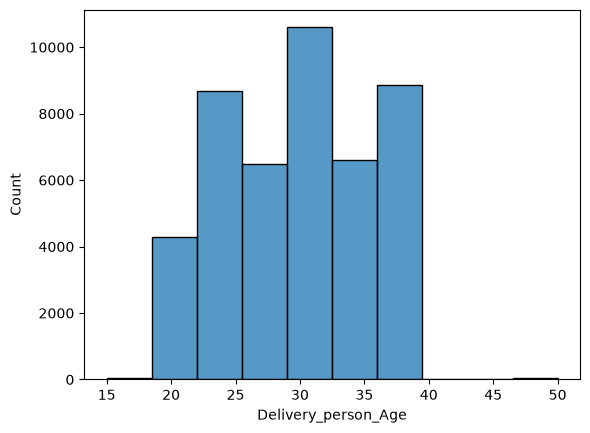

In [50]:
sns.histplot(df['Delivery_person_Age'],bins=10)

In [51]:
# How many riders are over 40? (checking the tail of the age distribution)

df[df['Delivery_person_Age']>40]['Delivery_person_Age'].shape

(53,)

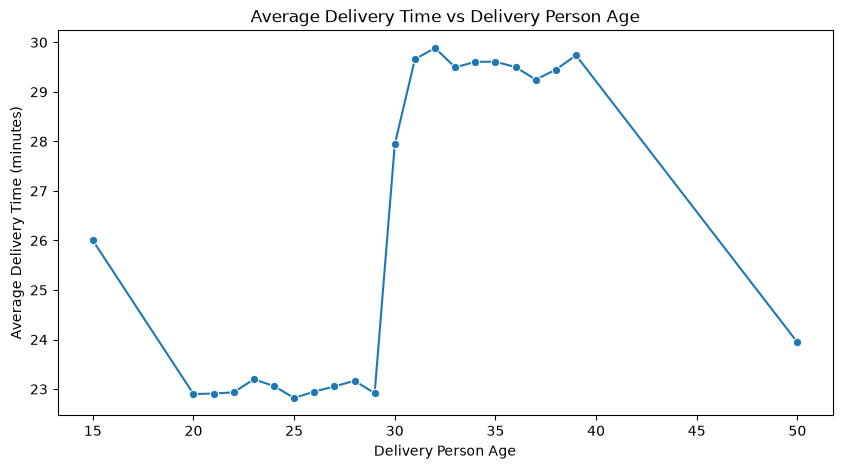

In [52]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=df,
    x="Delivery_person_Age",
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Delivery Time vs Delivery Person Age")
plt.xlabel("Delivery Person Age")
plt.ylabel("Average Delivery Time (minutes)")

plt.show()
     

In [53]:
df['Delivery_person_Ratings'].describe()

count    45593.000000
mean         4.636552
std          0.327906
min          1.000000
25%          4.600000
50%          4.700000
75%          4.800000
max          6.000000
Name: Delivery_person_Ratings, dtype: float64

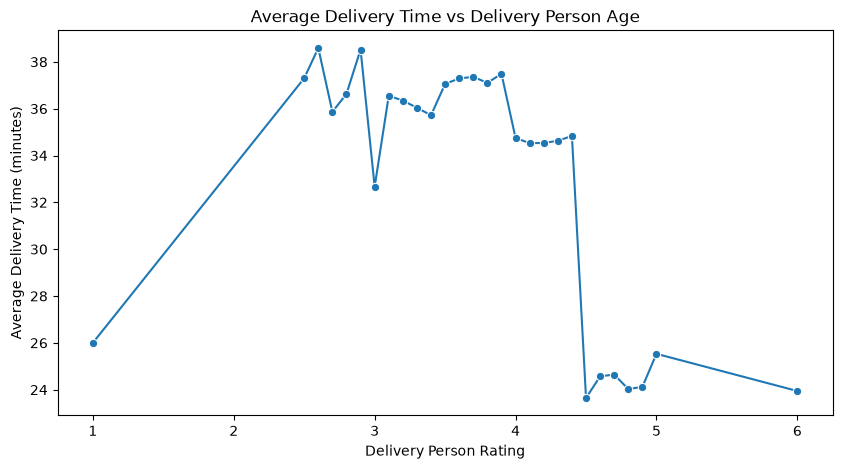

In [54]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=df,
    x='Delivery_person_Ratings',
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Delivery Time vs Delivery Person Age")
plt.xlabel("Delivery Person Rating")
plt.ylabel("Average Delivery Time (minutes)")

plt.show()

In [55]:
# Share of deliveries by low-rated (<4) riders
df[df['Delivery_person_Ratings']<4].shape[0]/len(df)

0.02998267277871603

# Correlation Heatmap (numeric columns so far)

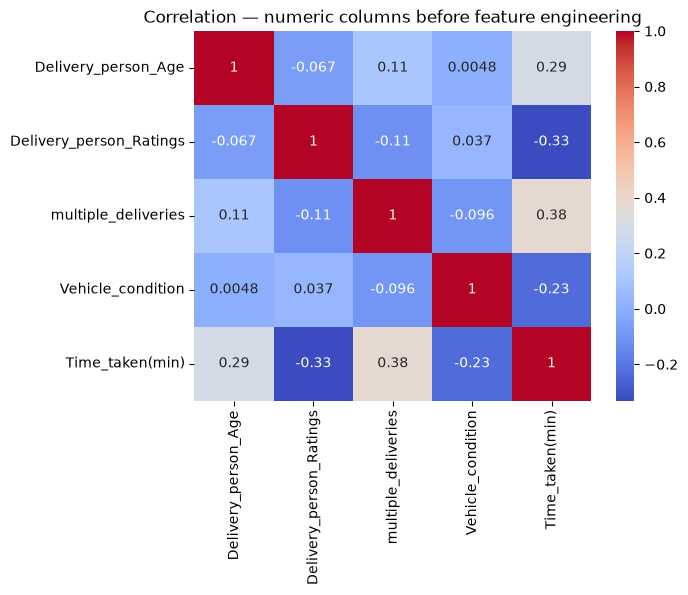

In [56]:
numeric_cols=['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries','Vehicle_condition','Time_taken(min)']
sns.heatmap(df[numeric_cols].corr(),annot=True,cmap='coolwarm')
plt.title('Correlation — numeric columns before feature engineering')
plt.show()
     

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

# 4. Feature engineering

In [58]:
# Raw date column (stored as text)
df['Order_Date']

0        19-03-2022
1        25-03-2022
2        19-03-2022
3        05-04-2022
4        26-03-2022
            ...    
45588    24-03-2022
45589    16-02-2022
45590    11-03-2022
45591    07-03-2022
45592    02-03-2022
Name: Order_Date, Length: 45593, dtype: str

In [59]:
# Raw order-time column (stored as text) — we'll extract the hour from this
df['Time_Orderd']
     

0        11:30:00
1        19:45:00
2        08:30:00
3        18:00:00
4        13:30:00
           ...   
45588    11:35:00
45589    19:55:00
45590    23:50:00
45591    13:35:00
45592    17:10:00
Name: Time_Orderd, Length: 45593, dtype: str

In [60]:

# Parse the time and pull out the hour; errors='coerce' turns unparseable times into NaT

hour=pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S', errors='coerce').dt.hour

In [61]:
hour.unique()

array([11., 19.,  8., 18., 13., 21., 17., 20., 14.,  9., 22., 12., 23.,
       nan, 10., 16., 15.,  0.])

In [62]:

# Does the hour of day relate to delivery time? (rush hours should stand out)
df.groupby(hour)['Time_taken(min)'].agg(['mean','median'])

,mean,median
Time_Orderd,,
0.0,22.169767,21.0
8.0,19.584158,19.0
9.0,19.543914,19.0
10.0,19.482170,19.0
11.0,26.380734,27.0
12.0,26.826233,27.0
13.0,27.538265,27.0
14.0,27.537295,27.0
15.0,23.194731,23.0


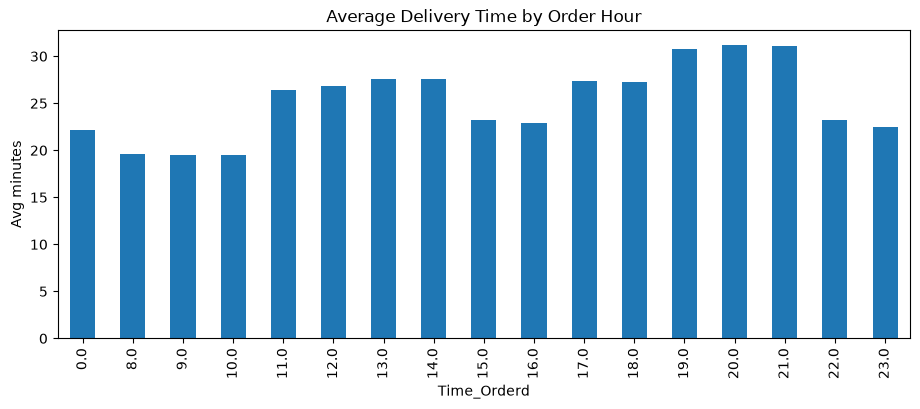

In [63]:
df.groupby(hour)['Time_taken(min)'].mean().plot(kind='bar',figsize=(11,4))
plt.title('Average Delivery Time by Order Hour')
plt.ylabel('Avg minutes')
plt.show()
     


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

# Distance from coordinates — the Haversine formula

In [65]:
def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of

    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """
    r = 3956 if miles else 6371
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * r


In [66]:
df['distance_km']=calculate_series_distance(df['Restaurant_latitude'],df['Restaurant_longitude'],df['Delivery_location_latitude'],df['Delivery_location_longitude'])

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [68]:
df['distance_km'].describe()

count    45593.000000
mean        99.303911
std       1099.731281
min          1.465067
25%          4.663493
50%          9.264281
75%         13.763977
max      19692.674606
Name: distance_km, dtype: float64

In [69]:
# The >100 km rows: inspect the extreme distances (likely corrupt coordinates)
df[df['distance_km']>100]['distance_km'].describe()

count      431.000000
mean      9484.671093
std       6252.618252
min       2216.065794
25%       4434.856783
50%       5897.015762
75%      17132.390571
max      19692.674606
Name: distance_km, dtype: float64

In [70]:
df[df['distance_km']>100]

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
92,0xc042,AGRRES010DEL01,34.0,4.7,-27.163303,78.057044,27.233303,78.127044,16-02-2022,23:00:00,...,Sandstorms,Low,1,Drinks,scooter,0.0,No,Metropolitian,15,6048.631240
283,0xc044,AGRRES12DEL03,32.0,4.7,-27.165108,78.015053,27.225108,78.075053,13-02-2022,20:55:00,...,Sandstorms,Jam,2,Meal,scooter,1.0,No,Metropolitian,31,6047.919478
289,0x4db,PUNERES02DEL03,30.0,4.7,-18.551440,-73.804855,18.611440,73.864855,05-03-2022,NaN,...,Stormy,Jam,2,Meal,scooter,0.0,No,Urban,12,16612.239055
425,0xc003,DEHRES13DEL02,30.0,4.7,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,...,Fog,Low,3,Snack,scooter,1.0,No,Metropolitian,20,17744.205087
534,0x473,MYSRES07DEL03,30.0,4.7,-12.325461,-76.632278,12.385461,76.692278,03-03-2022,NaN,...,Fog,Low,3,Buffet,scooter,1.0,No,Metropolitian,16,17118.828366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44933,0xc0c2,AURGRES03DEL03,30.0,4.9,-19.874733,75.353942,19.904733,75.383942,15-02-2022,22:20:00,...,Fog,Low,1,Buffet,motorcycle,0.0,No,Metropolitian,15,4423.276011
45020,0x56b,PUNERES04DEL01,30.0,4.7,-18.514210,73.838429,18.524210,73.848429,21-03-2022,NaN,...,Fog,Low,3,Drinks,electric_scooter,1.0,No,Metropolitian,30,4118.484540
45108,0xc01b,GOARES18DEL01,30.0,4.7,-15.493950,-73.827423,15.563950,73.897423,16-02-2022,NaN,...,Windy,Jam,2,Meal,scooter,1.0,No,Urban,19,16560.629487
45182,0xc0c7,KNPRES16DEL02,30.0,4.0,-26.482581,80.315628,26.532581,80.365628,17-02-2022,22:25:00,...,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,34,5895.019482


In [71]:

# The realistic (<100 km) trips: this is the range we'll keep
df[df['distance_km']<100]['distance_km'].describe()

count    45162.000000
mean         9.735396
std          5.608508
min          1.465067
25%          4.663412
50%          9.220209
75%         13.681490
max         20.969489
Name: distance_km, dtype: float64

In [72]:
# Hour of day the order was placed (0-23) — kept continuous, not binned (see note below)
df['order_hour']=pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S', errors='coerce').dt.hour
     

In [73]:
# A handful of unparseable timestamps become NaN hours — fill with the median hour
df['order_hour'].fillna(df['order_hour'].median(),inplace=True)

C:\Users\arnab\AppData\Local\Temp\ipykernel_19408\1417926182.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['order_hour'].fillna(df['order_hour'].median(),inplace=True)


0        11.0
1        19.0
2         8.0
3        18.0
4        13.0
         ... 
45588    11.0
45589    19.0
45590    23.0
45591    13.0
45592    17.0
Name: order_hour, Length: 45593, dtype: float64

In [74]:
df=df[df['distance_km']<100].reset_index(drop=True)

In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  str    
 1   Delivery_person_ID           45162 non-null  str    
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  str    
 9   Time_Orderd                  43706 non-null  str    
 10  Time_Order_picked            45162 non-null  str    
 11  Weatherconditions            45162 non-null  str    
 12  Road_traffic_density         45162 non-null  str    
 13  Vehicle_condition          

In [76]:
# Too many unique delivery-person IDs to one-hot encode — so we won't use the ID as a feature
len(df['Delivery_person_ID'].unique())
     

1320

# 5. Assemble the feature matrix X and target y

In [77]:

features=['Delivery_person_Age','Delivery_person_Ratings','distance_km','order_hour','Weatherconditions','Road_traffic_density',
          'Vehicle_condition','Type_of_order','Type_of_vehicle','multiple_deliveries','Festival','City']

In [78]:
X=df[features]

In [79]:
y=df['Time_taken(min)']

# 6. Encoding categorical variables

In [86]:
# Traffic density has a real order (Low < Medium < High < Jam) -> ordinal encode instead of one-hot,
# so the model can learn a single, sensible increasing relationship
traffic_mapping={
    'Low':0,
    'Medium': 1,
    'High' : 2,
    'Jam' : 3
}

X['Road_traffic_density']=X['Road_traffic_density'].map(traffic_mapping)

In [88]:
X['Road_traffic_density']

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
         ..
45157   NaN
45158   NaN
45159   NaN
45160   NaN
45161   NaN
Name: Road_traffic_density, Length: 45162, dtype: float64

In [89]:
print(X.columns.tolist())

['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'order_hour', 'Road_traffic_density', 'Vehicle_condition', 'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Windy']


In [90]:
X[['Weatherconditions_Fog',
   'Weatherconditions_Sandstorms',
   'Weatherconditions_Stormy',
   'Weatherconditions_Sunny',
   'Weatherconditions_Windy']].sum()

Weatherconditions_Fog           8071
Weatherconditions_Sandstorms    7442
Weatherconditions_Stormy        7544
Weatherconditions_Sunny         7238
Weatherconditions_Windy         7382
dtype: int64

In [91]:
weather_cols = [col for col in X.columns if col.startswith('Weatherconditions_')]

weather_counts = X[weather_cols].sum()
weather_percentage = (weather_counts / len(X) * 100).round(2)

print(weather_percentage)

Weatherconditions_Fog           17.87
Weatherconditions_Sandstorms    16.48
Weatherconditions_Stormy        16.70
Weatherconditions_Sunny         16.03
Weatherconditions_Windy         16.35
dtype: float64


In [92]:
print("Total rows:", len(X))
print("Weather category counts:", weather_counts.sum())

Total rows: 45162
Weather category counts: 37677


In [93]:
X=pd.get_dummies(X,columns=['Type_of_order','Type_of_vehicle','Festival','City','Weatherconditions'],drop_first=True,dtype=int)

KeyError: "None of [Index(['Type_of_order', 'Type_of_vehicle', 'Festival', 'City',\n       'Weatherconditions'],\n      dtype='str')] are in the [columns]"

In [94]:
print(X.shape)
print(X.columns.tolist())

(45162, 21)
['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'order_hour', 'Road_traffic_density', 'Vehicle_condition', 'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Windy']


# 7. Train / test split

In [96]:
from sklearn.model_selection import train_test_split

In [97]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [98]:
# Confirm the split sizes (~80% train / ~20% test)
X_train.shape,X_test.shape

((36129, 21), (9033, 21))

# 8. Feature scaling (standardization)

In [99]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
     

In [100]:

# Fit the scaler on TRAIN ONLY, then apply it to both — never fit on test data 

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [101]:
import numpy as np

print("Missing values:", X_train.isna().sum().sum())
print("Infinite values:", np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

Missing values: 37294
Infinite values: 0


In [102]:
X_train.isna().sum()[X_train.isna().sum() > 0].sort_values(ascending=False)

Road_traffic_density    36129
order_hour               1165
dtype: int64

In [104]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Impute missing values using training data only
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# 2. Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

G:\Windows installer\anaconda\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Road_traffic_density']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
G:\Windows installer\anaconda\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Road_traffic_density']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [105]:
print(X_train['Road_traffic_density'].value_counts(dropna=False))
print("Non-missing:", X_train['Road_traffic_density'].notna().sum())


Road_traffic_density
NaN    36129
Name: count, dtype: int64
Non-missing: 0


In [106]:
print(X['Road_traffic_density'].value_counts(dropna=False))

Road_traffic_density
NaN    45162
Name: count, dtype: int64


In [107]:
traffic_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2,
    'Jam': 3
}

df['Road_traffic_density'] = df['Road_traffic_density'].map(traffic_mapping)

In [108]:
print(df['Road_traffic_density'].value_counts(dropna=False))

Road_traffic_density
0    15826
3    14050
1    10886
2     4400
Name: count, dtype: int64


In [109]:
# Fit the scaler on TRAIN ONLY, then apply it to both — never fit on test data
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
     

G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [110]:
# Note: scaling returns a plain numpy array — column names and index are lost here
X_train_scaled
     

array([[-1.33517305,  0.50604581, -0.35171278, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 1.12628719,  0.19521208,  1.34683601, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [-0.80771728, -0.42645537,  1.30714108, ...,  2.23997508,
        -0.43645196, -0.44093773],
       ...,
       [ 1.65374296, -0.11562165, -0.67284161, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 0.77465001,  0.50604581, -1.18141457, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [ 0.77465001, -1.35895655,  0.65355565, ..., -0.44643354,
        -0.43645196, -0.44093773]], shape=(36129, 21))

In [112]:
 #Put back into DataFrames with the original column names/index for readability
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns,index=X_train.index)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)
     

In [113]:
import joblib
# Save the fitted scaler
joblib.dump(scaler, "standard_scaler.pkl")
     

['standard_scaler.pkl']

# Model 1 — Linear Regression (baseline)

In [114]:
from sklearn.linear_model import LinearRegression

In [115]:
lr=LinearRegression()

In [116]:
lr.fit(X_train_scaled,y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [117]:
import numpy as np

print("NaN in X_train:", X_train.isna().sum().sum())
print("NaN in X_train_scaled:", np.isnan(X_train_scaled).sum())

NaN in X_train: 37294
NaN in X_train_scaled: Delivery_person_Age                     0
Delivery_person_Ratings                 0
distance_km                             0
order_hour                           1165
Road_traffic_density                36129
Vehicle_condition                       0
multiple_deliveries                     0
Type_of_order_Drinks                    0
Type_of_order_Meal                      0
Type_of_order_Snack                     0
Type_of_vehicle_electric_scooter        0
Type_of_vehicle_motorcycle              0
Type_of_vehicle_scooter                 0
Festival_Yes                            0
City_Semi-Urban                         0
City_Urban                              0
Weatherconditions_Fog                   0
Weatherconditions_Sandstorms            0
Weatherconditions_Stormy                0
Weatherconditions_Sunny                 0
Weatherconditions_Windy                 0
dtype: int64


In [118]:
print(X_train.columns[X_train.isna().any()].tolist())

['order_hour', 'Road_traffic_density']


In [119]:
X_train = X_train.drop(columns=['Road_traffic_density'])
X_test = X_test.drop(columns=['Road_traffic_density'])

In [120]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [121]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[ 2.2 ,-2.24, 2.33,...,-0.99,-2.23,-0.91]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](20,)","[293.1 ,247.37,220.12,...,109.27, 84.68, 8.81]"


In [122]:
y_pred = lr.predict(X_test_scaled)

In [123]:
lr.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[ 2.2 ,-2.24, 2.33,...,-0.99,-2.23,-0.91]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](20,)","[293.1 ,247.37,220.12,...,109.27, 84.68, 8.81]"


In [124]:
# One coefficient per feature (in the scaled space) — larger magnitude = bigger influence
lr.coef_

array([ 2.20137989, -2.2444652 ,  2.32627988, -0.04241042, -1.70941755,
        2.06362809, -0.07717252, -0.02210097, -0.02340254,  0.28613217,
        0.30370349,  0.04971557,  1.57490209,  0.71261465, -0.9582084 ,
        0.0424523 , -0.95290536, -0.985248  , -2.23031423, -0.91475905])

In [125]:
# Line the coefficients up with their feature names to read off which features matter most
X_train.columns
     

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Vehicle_condition', 'multiple_deliveries',
       'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack',
       'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle',
       'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban',
       'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms',
       'Weatherconditions_Stormy', 'Weatherconditions_Sunny',
       'Weatherconditions_Windy'],
      dtype='str')

In [126]:
from sklearn.metrics import r2_score,mean_squared_error

In [127]:
# Predictions on the held-out test set
y_pred_test=lr.predict(X_test_scaled)
     


In [128]:
# Test RMSE (average error in minutes)
rmse_test=np.sqrt(mean_squared_error(y_test,y_pred_test))
     

In [129]:
# Train RMSE — compare with test RMSE to check for overfitting
rmse_train=np.sqrt(mean_squared_error(y_train,lr.predict(X_train_scaled)))
     

In [130]:
r2_test=r2_score(y_test,y_pred_test)

In [131]:
r2_train=r2_score(y_train,lr.predict(X_train_scaled))

In [132]:

# Train: RMSE, R²
print(rmse_train,r2_train)

6.65060437092729 0.49543222444884494


In [133]:
# Test: RMSE, R²  — close to train, so the linear model underfits rather than overfits
print(rmse_test,r2_test)

6.80285004475482 0.48357562072803395


# Model 2 — Decision Tree

In [134]:
from sklearn.tree import DecisionTreeRegressor

In [135]:
dt=DecisionTreeRegressor(random_state=42)

In [136]:
dt.fit(X_train_scaled,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [137]:
y_pred_dt=dt.predict(X_test_scaled)

In [138]:
# Test performance

from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,dt.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,dt.predict(X_test_scaled))
print("dt rmse",rmse)
print("dt r2",r2)
     

dt rmse 5.7430038686372225
dt r2 0.6319531051440952


In [139]:
# Now check TRAIN performance for comparison — this is how we catch overfitting

from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_train,dt.predict(X_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train,dt.predict(X_train_scaled))
print("dt train rmse",rmse)
print("dt train r2",r2)

dt train rmse 0.07078012363390071
dt train r2 0.9999428495153599


# Model 3 — Random Forest

In [140]:
from sklearn.ensemble import RandomForestRegressor

In [141]:
rf=RandomForestRegressor(n_estimators=100,random_state=42)

In [142]:
rf.fit(X_train_scaled,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [143]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,rf.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,rf.predict(X_test_scaled))
print("rf rmse",rmse)
print("rf r2",r2)
     

rf rmse 4.307932957616384
rf r2 0.7929082432332228


In [144]:
#train data
mse=mean_squared_error(y_train,rf.predict(X_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train,rf.predict(X_train_scaled))
print("rf rmse",rmse)
print("rf r2",r2)
     

rf rmse 1.5955234157877
rf r2 0.9709595295013123


In [145]:
# from sklearn.model_selection import RandomizedSearchCV

# rf_param_dist={
#     'n_estimators':[200,300,400,500],
#     'max_depth':[10,15,20,25,None],
#     'min_samples_leaf':[1,2,4],
#     'min_samples_split':[2,5,10],
#     'max_features':['sqrt','log2',0.5]
# }
# # Sample 25 random combinations instead of testing every combination exhaustively
# rf_search=RandomizedSearchCV(RandomForestRegressor(random_state=42),rf_param_dist,n_iter=25,cv=3,scoring='r2',random_state=42,n_jobs=-1)
# rf_search.fit(X_train_scaled,y_train)
# print("best params",rf_search.best_params_)
# rf_best=rf_search.best_estimator_
     

In [146]:
# r2_rf_tuned=r2_score(y_test,rf_best.predict(X_test_scaled))
# rmse_rf_tuned=np.sqrt(mean_squared_error(y_test,rf_best.predict(X_test_scaled)))
# print("tuned rf rmse",rmse_rf_tuned)
# print("tuned rf r2",r2_rf_tuned)

In [147]:

# Which features the forest actually leans on
# rf.feature_importances_
     

In [148]:

# Feature order (useful for interpreting coefficients / importances)
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Vehicle_condition', 'multiple_deliveries',
       'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack',
       'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle',
       'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban',
       'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms',
       'Weatherconditions_Stormy', 'Weatherconditions_Sunny',
       'Weatherconditions_Windy'],
      dtype='str')

# Model 4 — XGBoost

In [152]:
import sys
!{sys.executable} -m pip install xgboost

'G:\Windows' is not recognized as an internal or external command,
operable program or batch file.


In [154]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 3.7 MB/s eta 0:00:13
   - -------------------------------------- 1.3/48.9 MB 2.7 MB/s eta 0:00:18
   - -------------------------------------- 2.1/48.9 MB 3.2 MB/s eta 0:00:15
   -- ------------------------------------- 3.1/48.9 MB 3.3 MB/s eta 0:00:14
   --- ------------------------------------ 4.2/48.9 MB 3.7 MB/s eta 0:00:13
   --- ------------------------------------ 4.7/48.9 MB 3.5 MB/s eta 0:00:13
   ---- ----------------------------------- 5.8/48.9 MB 3.7 MB/s eta 0:00:12
   ----- ---------------------------------- 6.8/48.9 MB 3.9 MB/s eta 0:00:11
   ----- ---------------------------------- 7.3/48.9 MB 3.9 MB/s eta 0:00:11
   ------ --------------------------------- 8.4/48.9 MB 3.9 MB/s eta 0:00:11
   ------- -

In [157]:
import xgboost
print(xgboost.__version__)

ModuleNotFoundError: No module named 'xgboost'

In [158]:

import sys
print("Python path:", sys.executable)

%pip install xgboost


Python path: G:\Windows installer\anaconda\python.exe
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [159]:
import site
import sys

user_site = site.getusersitepackages()
print(user_site)

if user_site not in sys.path:
    sys.path.append(user_site)

C:\Users\arnab\AppData\Roaming\Python\Python314\site-packages


In [160]:
import sys

sys.path.append(
    r"C:\Users\arnab\AppData\Roaming\Python\Python314\site-packages"
)

from xgboost import XGBRegressor

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [161]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [162]:
y_pred_xgb = xgb.predict(X_test)

In [163]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred_xgb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))
print("R2 Score:", r2_score(y_test, y_pred_xgb))

MAE: 3.3218090534210205
RMSE: 4.242122305409491
R2 Score: 0.7991872429847717


In [167]:
from sklearn.metrics import r2_score

y_test_pred = xgb.predict(X_test)

r2_xgb_test = r2_score(y_test, y_test_pred)

n_test = len(y_test)
p_test = X_test.shape[1]

adj_r2_xgb_test = 1 - (1 - r2_xgb_test) * (n_test - 1) / (n_test - p_test - 1)

print("XGBoost Test R²:", r2_xgb_test)
print("XGBoost Test Adjusted R²:", adj_r2_xgb_test)

XGBoost Test R²: 0.7991872429847717
XGBoost Test Adjusted R²: 0.7987415866221104


In [168]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("MAE:", mae, "minutes")
print("RMSE:", rmse, "minutes")

MAE: 3.3218090534210205 minutes
RMSE: 4.242122305409491 minutes


In [169]:
# Bucket the order hour into meal periods (lunch / dinner rushes vs the rest)
def order_period(hour):
  if 12<=hour<=14 :
    return "Lunch"
  elif 19<=hour<=21 :
    return "Dinner"
  else :
    return "Normal"
     

In [170]:
# 1. Copy unscaled data
X_train_exp = X_train.copy()
X_test_exp = X_test.copy()

In [171]:
# 2. Create the new feature BEFORE scaling
X_train_exp['order_period'] = X_train_exp['order_hour'].apply(order_period)
X_test_exp['order_period'] = X_test_exp['order_hour'].apply(order_period)

In [172]:
# Confirm the new order_period column landed correctly
X_train_exp
     

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,Type_of_vehicle_electric_scooter,...,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy,order_period
24844,22.0,4.8,7.762944,17.0,2,1.0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,Normal
33010,36.0,4.7,17.297866,21.0,2,2.0,1,0,0,0,...,1,1,0,0,0,0,0,0,0,Dinner
16599,25.0,4.5,17.075035,21.0,2,0.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,Dinner
35248,38.0,4.8,3.040816,11.0,1,0.0,0,1,0,0,...,1,0,0,0,0,0,1,0,0,Normal
14293,26.0,5.0,3.145067,8.0,0,1.0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,38.0,4.9,4.657592,21.0,0,1.0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,Dinner
44732,30.0,4.7,20.181187,23.0,0,0.0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,Normal
38158,39.0,4.6,5.960265,13.0,2,1.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,Lunch
860,34.0,4.8,3.105356,8.0,1,1.0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,Normal


In [173]:
# 3. One-hot encode
X_train_exp = pd.get_dummies(
    X_train_exp, columns=['order_period'], drop_first=True, dtype=int
)

X_test_exp = pd.get_dummies(
    X_test_exp, columns=['order_period'], drop_first=True, dtype=int
)

     

In [178]:
# 4. Create a NEW scaler and fit ONLY on expanded training data
scaler_exp = StandardScaler()

X_train_exp_scaled = scaler_exp.fit_transform(X_train_exp)
X_test_exp_scaled = scaler_exp.transform(X_test_exp)

In [179]:
# Reuse the original model's parameters
params = xgb.get_params()

xgb_with_period = XGBRegressor(**params)

xgb_with_period.fit(X_train_exp_scaled, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [180]:
%whos

Variable                    Type                     Data/Info
--------------------------------------------------------------
DecisionTreeRegressor       ABCMeta                  <class 'sklearn.tree._cla<...>s.DecisionTreeRegressor'>
LinearRegression            ABCMeta                  <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor       ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
SimpleImputer               type                     <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler              type                     <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                           DataFrame                Shape: (45162, 21)
XGBRegressor                type                     <class 'xgboost.sklearn.XGBRegressor'>
X_test                      DataFrame                Shape: (9033, 20)
X_test_exp                  DataFrame                Shape: (9033, 22)
X_test_exp_scaled           ndarra

In [181]:
y_pred_period = xgb_with_period.predict(X_test_exp_scaled)

In [182]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_new = mean_absolute_error(y_test, y_pred_period)
rmse_new = np.sqrt(mean_squared_error(y_test, y_pred_period))
r2_new = r2_score(y_test, y_pred_period)

print("XGBoost with Order Period")
print("MAE:", round(mae_new, 3))
print("RMSE:", round(rmse_new, 3))
print("R²:", round(r2_new, 4))

XGBoost with Order Period
MAE: 3.308
RMSE: 4.216
R²: 0.8016


In [183]:
import pandas as pd

importance = pd.Series(
    xgb_with_period.feature_importances_,
    index=X_train_exp.columns
).sort_values(ascending=False)

print(importance.head(10))

order_period_Normal             0.164018
multiple_deliveries             0.125738
Weatherconditions_Sunny         0.118767
Delivery_person_Ratings         0.102214
Festival_Yes                    0.090693
Weatherconditions_Fog           0.085721
Vehicle_condition               0.064365
order_hour                      0.044162
Weatherconditions_Sandstorms    0.034415
Delivery_person_Age             0.032736
dtype: float32


In [184]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original model predictions
y_pred_original = xgb.predict(X_test)

# New model predictions
y_pred_period = xgb_with_period.predict(X_test_exp_scaled)

# Comparison function
def evaluate_model(y_true, y_pred, name):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_model(y_test, y_pred_original, "Original XGBoost"),
    evaluate_model(y_test, y_pred_period, "XGBoost + Order Period")
])

print(results.round(4))

                    Model     MAE    RMSE  R2 Score
0        Original XGBoost  3.3218  4.2421    0.7992
1  XGBoost + Order Period  3.3084  4.2164    0.8016


In [185]:
n_test = X_test_exp.shape[0]
p_test = X_test_exp.shape[1]
r2_with_period_test = r2_score(y_test, xgb_with_period.predict(X_test_exp_scaled))
adj_r2_test = 1 - (1 - r2_with_period_test) * (n_test - 1) / (n_test - p_test - 1)
print("Test Adjusted R²:", adj_r2_test)
     

Test Adjusted R²: 0.8011333453933089


# Results & model persistence

In [186]:
results = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "MAE": 3.3218,
        "RMSE": 4.2421,
        "R2 Score": 0.7992
    },
    {
        "Model": "XGBoost + Order Period",
        "MAE": 3.3084,
        "RMSE": 4.2164,
        "R2 Score": 0.8016
    }
])

print(results)

                    Model     MAE    RMSE  R2 Score
0        Original XGBoost  3.3218  4.2421    0.7992
1  XGBoost + Order Period  3.3084  4.2164    0.8016


In [187]:
import joblib

joblib.dump(xgb_with_period, "food_delivery_xgboost.pkl")

print("Model saved successfully!")

Model saved successfully!


In [188]:
joblib.dump(imputer, "food_delivery_imputer.pkl")
joblib.dump(scaler, "food_delivery_scaler.pkl")

['food_delivery_scaler.pkl']

In [189]:
# Grab 3 raw (unscaled) test rows to mimic new incoming orders
sample=X_test[0:3]
     


In [191]:
# Apply the SAME scaler the model was trained with
sample_scaled = scaler.transform(sample)

G:\Windows installer\anaconda\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [192]:
sample_scaled = scaler.transform(sample.to_numpy())

In [193]:
print("Sample shape:", sample.shape)
print("Expected features:", scaler.n_features_in_)

Sample shape: (3, 20)
Expected features: 20


In [196]:
# Model's predicted minutes
predictions
     

NameError: name 'predictions' is not defined